In [1]:
# optimize cells based on kalmbach_2021
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/users/kduecker/hnn-tuning/local_hnn/hnn_core/mod'
#figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn_dev/figures/newl5_hay/'
# import os
# os.mkdir(figpth)
from cell_builder_utils import l5_params, _get_dends, _get_pyr_soma, Cell
from hay_mechs_utils import Mechs
from plot_utils import fig_conductances, fig_compartments
from functools import partial

from hnn_core.viz import plot_cell_morphology

import pandas as pd
from scipy import signal
from plot_utils import fig_conductances, fig_compartments
from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
from scipy.signal import find_peaks
from scipy.fft import fft, fftfreq
from scipy.signal import windows
from scipy.signal import chirp

import pygad
os.chdir('/users/kduecker/hnn-tuning')

from hay_mechs_utils import Mechs, Ih_condu_apical, linear_gbar
import pickle

--No graphics will be displayed.


In [8]:
# load electrophysio from Kalmbach, 2021

df = pd.read_csv(os.path.join('data','kalmbach_2021_l5_electrophys.csv'))

df['etype'].value_counts() # 1 seems to be the E-type cells

l5df = df[df['etype'] == 1]

ephys_measures = dict()
ephys_measures['target_rmp'] = np.mean(l5df['RMP'].values)

ephys_measures['sag_ratio'] = np.mean(l5df['Sag_ratio'])

ephys_measures['rebound'] = np.mean(l5df['Rebound'])

ephys_measures['res_freq'] = np.mean(l5df['Fr'])

ephys_measures['ap_thresh'] = np.mean(l5df['AP_threshold'])

ephys_measures['ap_peak'] = np.mean(l5df['AP_peak'])
ephys_measures['AP_HW'] = l5df['AP_HW'] # AP half width

ephys_measures['fi_slope'] = np.mean(l5df['FI_slope_max'])
ephys_measures['min_burst_ISI_5'] = l5df['min_burst_ISI_5'] # min ISI during first 50 ms of continous current


ephys_measures['ss_inp_res'] = np.mean(l5df['SSRn'])

ephys_measures['f_AHP'] = l5df['f_AHP'] # fast afterhyperpolarization relative to threshold




In [13]:
from l5_optimize_slurm import return_start_params, rmp_grad, load_data, ap_measures, fi_slope, rebound, add_condu_cell


In [41]:
neuron.load_mechanisms(pth_mod)
h.load_file("stdrun.hoc")

# start parameters (hand-tuned conductances)
start_params = return_start_params()
hand_tuned_condu = np.array(list(start_params.values()))

# cell morphology and sections
keys = list(start_params.keys())

# Find resting membrane potential
section_params, end_pts, cell_tree = l5_params()

# build sections
section_names = list(end_pts.keys())

sections = _get_dends(section_params, 'L5Pyr', section_names, end_pts, v_init={'all': -60})
sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr', end_pts['soma'], v_init=-60)

mech_class = Mechs(pth_mod)

# build model
hotzone = [1500, 2000]

conductances = hand_tuned_condu

# Get morphological parameters
section_params, end_pts, cell_tree = l5_params()
sections = _get_dends(section_params, 'L5Pyr', list(end_pts.keys()), end_pts, v_init={'all': -60})
sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr', end_pts['soma'], v_init=-60)
hotzone = [1500, 2000]

# Single AP
l5pyr = Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = add_condu_cell(l5pyr, keys, conductances)

stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 3
stim.amp = 3
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.dt = .01
h.finitialize()
h.continuerun(50 * ms)

ap, properties = find_peaks(v_soma.as_numpy(), height=0, width=0)

ap_trough = np.argmin(v_soma)

v_grad = np.gradient(v_soma)
ap_thresh_idx = np.argmin(np.abs(v_grad-np.max(v_grad)*.09))
ap_thresh = v_soma[ap_thresh_idx]

if len(ap) > 0:
    ap_peak = properties['peak_heights'][0]
else:
    ap_peak = v_soma[-1]

half_max = np.min(v_soma.as_numpy()) + (np.max(v_soma.as_numpy())-np.min(v_soma.as_numpy()))/2
idx1 = np.argmin(np.abs(v_soma.as_numpy()[ap_thresh_idx:int(ap)]-half_max))
idx2 = np.argmin(np.abs(v_soma.as_numpy()[int(ap):ap_trough]-half_max))


ap_hw = t.as_numpy()[idx2+int(ap)]-t.as_numpy()[idx1+ap_thresh_idx]

f_AHP = np.min(soma_voltg.as_numpy()) - ap_thresh

Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.


/tmp/ipykernel_605234/4062722283.py:66: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  idx1 = np.argmin(np.abs(v_soma.as_numpy()[ap_thresh_idx:int(ap)]-half_max))
/tmp/ipykernel_605234/4062722283.py:67: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  idx2 = np.argmin(np.abs(v_soma.as_numpy()[int(ap):ap_trough]-half_max))
/tmp/ipykernel_605234/4062722283.py:70: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  ap_hw = t.as_numpy()[idx2+int(ap)]-t.as_numpy()[idx1+ap_thresh_

In [25]:
# 50 ms ISI (burst)

l5pyr = Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
l5pyr.build()
l5pyr = add_condu_cell(l5pyr, keys, conductances)

stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 1
stim.dur = 1000
stim.amp = 0.8

t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(50 * ms)

#soma_voltg = soma_voltg.as_numpy()

spk, prop = signal.find_peaks(soma_voltg, height=0)


min_burst_isi = np.mean(np.diff(t.as_numpy()[spk]))

/tmp/ipykernel_605234/2527414991.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.plot(t.as_numpy()[idx2+int(ap)],v_soma.as_numpy()[idx2+int(ap)],'o')


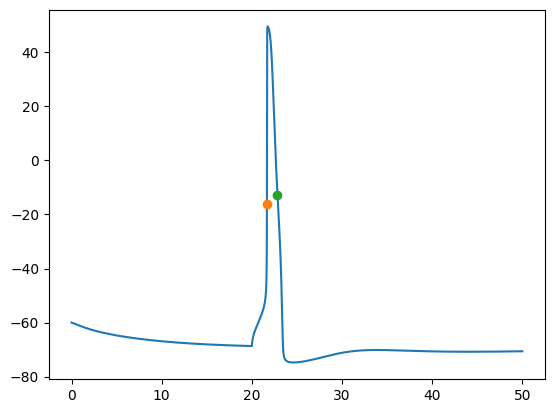

In [18]:
plt.plot(t,v_soma)

plt.plot(t.as_numpy()[idx1+ap_thresh_idx],v_soma.as_numpy()[idx1+ap_thresh_idx],'o')
plt.plot(t.as_numpy()[idx2+int(ap)],v_soma.as_numpy()[idx2+int(ap)],'o')


In [3]:
def fitness_function(ga_instance, solution, solution_idx):

    ephys_measures = load_data('/users/kduecker/hnn-tuning/data/kalmbach_2021_l5_electrophys.csv')


    # start parameters (hand-tuned conductances)
    start_params = return_start_params()
    hand_tuned_condu = np.array(list(start_params.values()))

    # cell morphology and sections
    keys = list(start_params.keys())

    # Find resting membrane potential
    section_params, end_pts, cell_tree = l5_params()

    # build sections
    section_names = list(end_pts.keys())

    sections = _get_dends(section_params, 'L5Pyr', section_names, end_pts, v_init={'all': -60})
    sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr', end_pts['soma'], v_init=-60)

    mech_class = Mechs(pth_mod)

    # build model
    hotzone = [1500, 2000]

    conductances = hand_tuned_condu*solution

    # Fintess
    fitness = np.zeros(4,)

    rmp, grad, pos_grad, soma_voltg, t = rmp_grad(sections, cell_tree, keys, conductances)

    # RMP
    fitness[0] = np.mean(np.array((1/(np.abs(rmp-ephys_measures['target_rmp'])+.01),1/(abs(0.05-grad)+0.01),1/pos_grad)));
    

    # AP measures
    ap_thresh, ap_peak, v_soma, t = ap_measures(sections, cell_tree, keys, conductances)

    ap_thresh_fit = 1/(np.abs(ap_thresh-ephys_measures['ap_thresh'])+0.01)
    ap_peak_fit = 1/(np.abs(ap_peak-ephys_measures['ap_peak'])+0.01)

    fitness[1] = np.mean(np.array((ap_thresh_fit, ap_peak_fit)))

    # FI slope
    fi_slo = fi_slope(sections, cell_tree, keys, conductances)

    fitness[2] = 1/(np.abs(fi_slo-ephys_measures['fi_slope'])+0.01)

    # Rebound

    rebound_model, sag_ratio_model, inp_res_max = rebound(sections, cell_tree, keys, conductances)

    inp_res = 1/(abs(inp_res_max-ephys_measures['ss_inp_res'])+0.01)
    
    reb = 1/(np.abs(rebound_model-ephys_measures['rebound'])+0.01)

    sagr = 1/(np.abs(sag_ratio_model-ephys_measures['sag_ratio'])+0.01)

    fitness[3] = (inp_res + reb + sagr)/3

    return fitness

In [4]:
def on_fitness(ga_instance, population_fitness):
    print("on_fitness()", flush=True)

def on_parents(ga_instance, selected_parents):
    print("on_parents()", flush=True)

def on_crossover(ga_instance, offspring_crossover):
    print("on_crossover()", flush=True)

def on_mutation(ga_instance, offspring_mutation):
    print("on_mutation()", flush=True)

def on_generation(ga_instance):

        print("Generation : ", ga_instance.generations_completed, flush=True)

        # current_gen = ga_instance.generations_completed
        # # Reduce population to 5 after generation 10
        # if current_gen % 10 == 0:
        #     ga_instance.population = ga_instance.population[:-10]  # Keep top solutions
        #     ga_instance.sol_per_pop -= 10  # Update population size
        #     ga_instance.num_parents_mating -=10  # Adjust parents to mate
        #     ga_instance.last_generation_fitness = ga_instance.cal_pop_fitness()
        #     ga_instance.

        # save
        np.save(f'/users/kduecker/hnn-tuning/new_model_dev/l5_last_gen_parents.npy', ga_instance.last_generation_parents)
        np.save(f'/users/kduecker/hnn-tuning/new_model_dev/l5_last_gen_parents_fit.npy',
                ga_instance.last_generation_fitness[ga_instance.last_generation_parents_indices])
        fitness_list.append(ga_instance.last_generation_fitness)
        np.save(f'/users/kduecker/hnn-tuning/new_model_dev/l5_generation_fitness.npy', np.array(fitness_list))
        parents_list.append(ga_instance.last_generation_parents)
        np.save(f'/users/kduecker/hnn-tuning/new_model_dev/l5_all_parents.npy', np.array(parents_list))

def on_stop(ga_instance, last_population_fitness):
    
    print("Done")
    best_sol = ga_instance.best_solution()

    with open('l5_best_sol.pkl', 'wb') as file:
        pickle.dump(best_sol, file)

In [5]:
ga_instance = pygad.load('new_model_dev/l5_pygad_inst')
ga_instance.num_generations += 100
ga_instance.run()

Can't pickle <function fitness_function_wrapper at 0x7f3f6c3aa5e0>: attribute lookup fitness_function_wrapper on __main__ failed
concurrent.futures.process._RemoteTraceback: 
"""
Traceback (most recent call last):
  File "/users/kduecker/.conda/envs/local_hnn/lib/python3.9/multiprocessing/queues.py", line 244, in _feed
    obj = _ForkingPickler.dumps(obj)
  File "/users/kduecker/.conda/envs/local_hnn/lib/python3.9/multiprocessing/reduction.py", line 51, in dumps
    cls(buf, protocol).dump(obj)
_pickle.PicklingError: Can't pickle <function fitness_function_wrapper at 0x7f3f6c3aa5e0>: attribute lookup fitness_function_wrapper on __main__ failed
"""

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/users/kduecker/.conda/envs/local_hnn/lib/python3.9/site-packages/pygad/pygad.py", line 1808, in cal_pop_fitness
    for index, fitness in zip(solutions_to_submit_indices, executor.map(self.fitness_func, [self]*len(solutions_to_su

PicklingError: Can't pickle <function fitness_function_wrapper at 0x7f3f6c3aa5e0>: attribute lookup fitness_function_wrapper on __main__ failed

In [12]:


start_params = return_start_params()  
hand_tuned_condu = np.array(list(start_params.values()))
initial_population = np.ones_like(hand_tuned_condu)
# RMP


In [13]:

num_gen = 100
num_parents_mating = 2

population_size = 10

gene_space = {'low': .01, 'high': 20}

initial_population_2d = np.concatenate((initial_population.reshape(1,-1),np.random.uniform(gene_space['low'], gene_space['high'],(population_size-1,hand_tuned_condu.shape[0]))))


In [14]:
# Use the fitness function with PyGAD

global fitness_list
global parents_list

fitness_list = []
parents_list = []



ga_instance = pygad.GA(num_generations=num_gen,
                    num_parents_mating=num_parents_mating,
                    keep_parents = 1,
                    fitness_func=fitness_function,
                    num_genes=len(start_params),
                    initial_population=initial_population_2d,
                    gene_space=gene_space,
                    on_fitness=on_fitness,
                    on_parents=on_parents,
                    on_crossover=on_crossover,
                    on_mutation=on_mutation,
                    on_generation=on_generation,
                    on_stop=on_stop,
            
                    parallel_processing=["process", 63])

ga_instance.run()

on_fitness()
on_parents()
on_crossover()
on_mutation()
Generation :  1
on_fitness()
on_parents()
on_crossover()
on_mutation()
Generation :  2
on_fitness()
on_parents()
on_crossover()
on_mutation()
Generation :  3
on_fitness()
on_parents()
on_crossover()
on_mutation()


In [ ]:
hand_tuned_condu = np.array(list(start_params.values()))

# cell morphology and sections
keys = list(start_params.keys())

# Find resting membrane potential
section_params, end_pts, cell_tree = l5_params()

# build sections
section_names = list(end_pts.keys())

v_init = {'soma': -65,
            'basal_1': -65,
            'basal_2': -65,
            'basal_3': -65,
            'apical_oblique': -65,
            'apical_trunk': -65,
            'apical_1': -65,
            'apical_2': -60,
            'apical_tuft': -54}

sections = _get_dends(section_params, 'L5Pyr', section_names, end_pts, v_init={'all': -60})
sections['soma'] = _get_pyr_soma(section_params, 'L5Pyr', end_pts['soma'], v_init=-60)

mech_class = Mechs(pth_mod)

# build model
hotzone = [1500, 2000]
best_sol = ga_instance.best_solution()[0]



conductances = hand_tuned_condu*best_sol

rmp, grad, pos_grad, soma_voltg, t = rmp_grad(sections, cell_tree, keys, conductances)

In [ ]:
plt.plot(t,soma_voltg)

In [ ]:
ephys_measures = load_data('/users/kduecker/hnn-tuning/data/kalmbach_2021_l5_electrophys.csv')
ephys_measures['target_rmp']

In [ ]:
ap_thresh, ap_peak, v_soma, t = ap_measures(sections, cell_tree, keys, conductances)

In [ ]:
plt.plot(t,v_soma)

In [ ]:
ap_peak, ephys_measures['ap_peak']

In [ ]:
ap_thresh, ephys_measures['ap_thresh']

In [ ]:
ephys_measures